# Figures 1, 2, and 3 of Pucha et al. (2026)

In [1]:
import numpy as np

from astropy.table import Table, join

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import ScalarFormatter
from scipy.stats import binned_statistic

import scipy.odr as odr
from scipy.optimize import curve_fit

from scipy.ndimage import gaussian_filter

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.5,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.5,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [4]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [5]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_snr = ha_b/t['HA_B_FLUX_ERR'].data
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_snr = ha_b_sig/t['HA_B_SIGMA_ERR'].data
per_broad = t['PROB_BROAD'].data

ha_b_lum = utils.Flux_to_Luminosity(ha_b*1e-17, z)
ha_b_fwhm = utils.sigma_to_fwhm(ha_b_sig)
bh_mass = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm)

In [6]:
## Number of two-component fits

is_sii_out = (t['SII6716_OUT_FLUX'].data != 0)
is_oiii_out = (t['OIII5007_OUT_FLUX'].data != 0)

print ('Number of sources with an extra [SII] component: ', len(t[is_sii_out]), round(len(t[is_sii_out])*100/len(t), 1), '%')
print ('Number of sources with an extra [OIII] component: ', len(t[is_oiii_out]), round(len(t[is_oiii_out])*100/len(t), 1), '%')

Number of sources with an extra [SII] component:  35666 0.6 %
Number of sources with an extra [OIII] component:  71618 1.2 %


In [7]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [8]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [9]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [10]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [11]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

#### M* vs. z

Text(0, 0.5, '$\\log~(M_{\\star}/M_{\\odot})$')

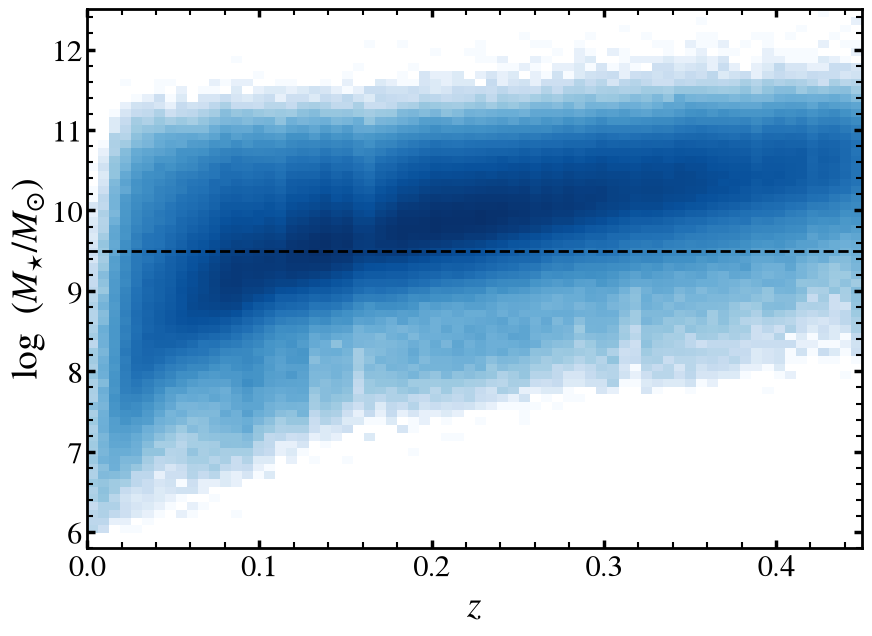

In [12]:
plt.figure(figsize = (10, 7))

hist1 = plt.hist2d(z[bpt_cut], logmass[bpt_cut], bins = 70, norm = LogNorm(), range = [[0, 0.45], [5.8, 12.5]], cmap = 'Blues')
plt.axhline(9.5, color = 'k', lw = 2.0, ls = '--')
plt.xlabel('$z$')
plt.ylabel('$\log~(M_{\star}/M_{\odot})$')

# plt.savefig('mstar_z_2dhist.png')

#### BPT Diagram

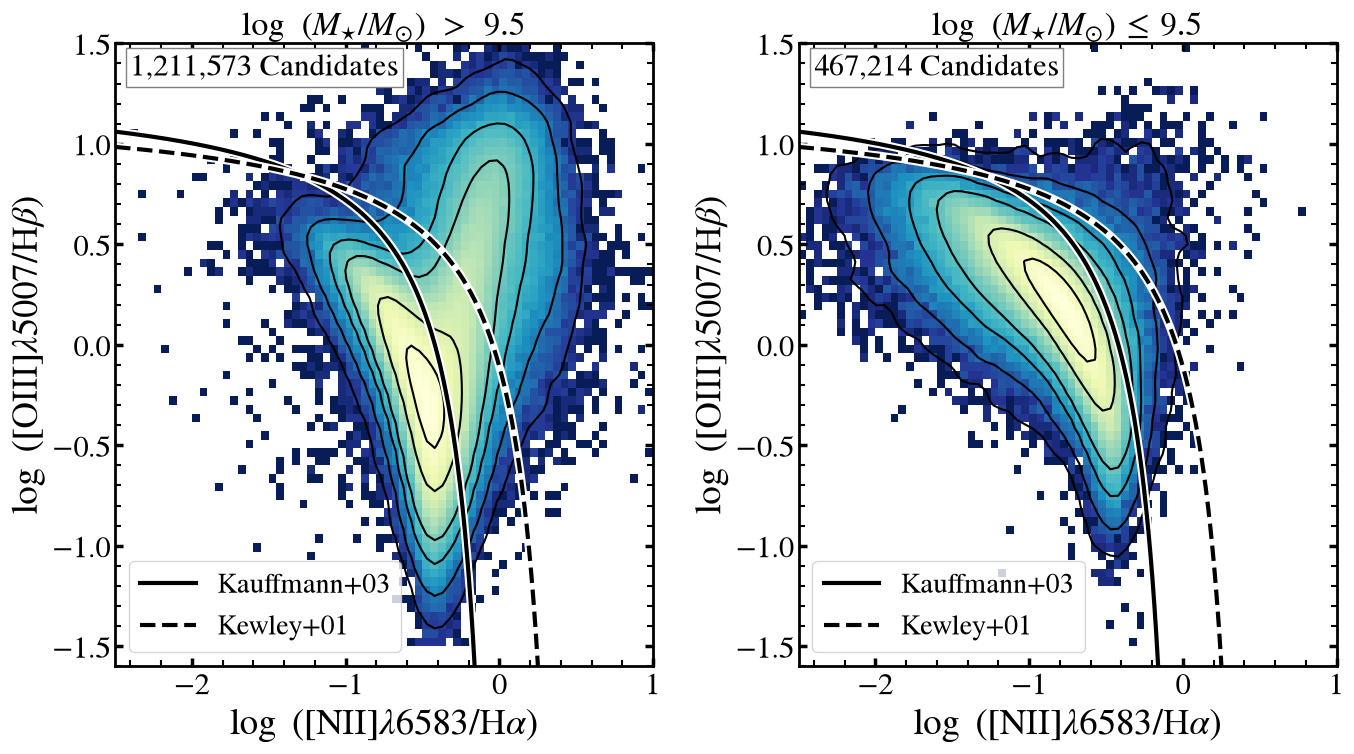

In [13]:
## Plot contours of BPT diagram for massive and dwarf galaxies
dens_lomass, _, _ = np.histogram2d(nii_ha[bpt_cut&lomass], oiii_hb[bpt_cut&lomass], bins = 70, range = [[-2.5, 1], [-1.5, 1.5]], density = True)
dens_himass, _, _ = np.histogram2d(nii_ha[bpt_cut&himass], oiii_hb[bpt_cut&himass], bins = 70, range = [[-2.5, 1], [-1.5, 1.5]], density = True)

# Apply Gaussian filter to smooth the density arrays
dens_himass_smooth = gaussian_filter(dens_himass, sigma=1)
dens_lomass_smooth = gaussian_filter(dens_lomass, sigma=1)

plt.figure(figsize = (14, 8))

plt.subplot2grid((1,2), (0,0))
plt.title('$\log~(M_{\star}/M_{\odot})~>~9.5$', fontsize = 24)
plt.hist2d(nii_ha[bpt_cut&himass], oiii_hb[bpt_cut&himass], bins = 70, norm = LogNorm(), range = [[-2.5, 1], [-1.5, 1.5]], cmap = 'YlGnBu_r')
# plt.colorbar(label = '# of Sources')
bpt.Plot_NII_BPT_Lines(Schawinsky = False, legend = True)
plt.contour(dens_himass_smooth.T, levels=[0.002, 0.01, 0.05, 0.15, 1.0, 3, 5], extent=[-2.5, 1, -1.5, 1.5], colors='k', linewidths=1.5, zorder=1)
plt.text(-2.4, 1.34, f'{len(nii_ha[bpt_cut&himass]):,} Candidates', fontsize = 22, bbox = dict(facecolor = 'white', edgecolor = 'grey', pad = 3))
plt.xlabel('$\log$ ([NII]$\lambda$6583/H$\\alpha$)')
plt.ylabel('$\log$ ([OIII]$\lambda$5007/H$\\beta$)')

plt.subplot2grid((1,2), (0,1))
plt.title('$\log~(M_{\star}/M_{\odot})~≤~9.5$', fontsize = 24)
plt.hist2d(nii_ha[bpt_cut&lomass], oiii_hb[bpt_cut&lomass], bins = 70, norm = LogNorm(), range = [[-2.5, 1], [-1.5, 1.5]], cmap = 'YlGnBu_r')
# plt.colorbar(label = '# of Sources')
plt.contour(dens_lomass_smooth.T, levels=[0.002, 0.01, 0.05, 0.15,  1.0, 3], extent=[-2.5, 1, -1.5, 1.5], colors='k', linewidths=1.5, zorder=1)
bpt.Plot_NII_BPT_Lines(Schawinsky = False, legend = True)
plt.text(-2.4, 1.34, f'{len(nii_ha[bpt_cut&lomass]):,} Candidates', fontsize = 22, bbox = dict(facecolor = 'white', edgecolor = 'grey', pad = 3))
plt.xlabel('$\log$ ([NII]$\lambda$6583/H$\\alpha$)')
plt.ylabel('$\log$ ([OIII]$\lambda$5007/H$\\beta$)')

plt.tight_layout()

# plt.savefig('bpt_all_2panel.png')

#### AGN Fraction vs. M*

In [14]:
## Define the logistic function
def logistic(x, L, k, x0):
    c = 100 - L
    return (L / (1 + np.exp(-k * (x - x0)))+c)

## Define a wrapper function for ODR
def logistic_odr(beta, x):
    return logistic(x, *beta)

In [15]:
def logistic_fit_output(xx, yy, xerr, yerr):
    ## Create an ODR Model
    model = odr.Model(logistic_odr)
    data = odr.RealData(xx, yy, sx = xerr, sy = yerr)
    odr_fit = odr.ODR(data, model, beta0 = [80, 0.5, 10.0])

    # Run the fit
    output = odr_fit.run()
    L_fit, k_fit, x0_fit = output.beta
    c_fit = 100 - L_fit

    return (L_fit, k_fit, x0_fit, c_fit)

In [16]:
def histedges_equalN(x, nbin):
    npt = len(x)
    edges = np.interp(np.linspace(0, npt, nbin+1), np.arange(npt), np.sort(x))
    
    return (edges)

In [17]:
def estimate_fractions(num, num_err, den, den_err):
    frac = num/den
    frac_err = frac*np.sqrt(((num_err/num)**2) + ((den_err/den)**2))

    return (frac, frac_err)

In [18]:
mbins = histedges_equalN(logmass, nbin = 20)

In [19]:
## Numbers in different bins

n_all, _ = np.histogram(logmass, bins = mbins)
nerr_all = np.sqrt(n_all)

n_leg, _ = np.histogram(logmass[bpt_cut], bins = mbins)
nerr_leg = np.sqrt(n_leg)

n_agn, _ = np.histogram(logmass[bpt_cut&(is_agn|is_comp)], bins = mbins)
nerr_agn = np.sqrt(n_agn)

In [20]:
## Logmass and AGN Fraction values in different bins

agnfrac_leg, agnfrac_leg_err = estimate_fractions(n_agn, nerr_agn, n_leg, nerr_leg)
agnfrac_all, agnfrac_all_err = estimate_fractions(n_agn, nerr_agn, n_all, nerr_all)

logmass_leg, _, _ = binned_statistic(logmass[bpt_cut], logmass[bpt_cut], bins = mbins, statistic = 'mean')
logmass_leg_err, _, _ = binned_statistic(logmass[bpt_cut], logmass[bpt_cut], bins = mbins, statistic = 'std')
logmass_tot, _, _ = binned_statistic(logmass, logmass, bins = mbins, statistic = 'mean')
logmass_tot_err, _, _ = binned_statistic(logmass, logmass, bins = mbins, statistic = 'std')

In [21]:
## Logistic Fir for the LEGs
xx = logmass_leg
yy = agnfrac_leg*100
xx_err = logmass_leg_err
yy_err = agnfrac_leg_err*100

L, k, x0, c = logistic_fit_output(xx, yy, xx_err, yy_err)
## Print Results
print (f"Fitted parameters: L = {L:.2f}, k = {k:.2f}, x0: {x0:.2f}, c = {c:.2f}")

Fitted parameters: L = 98.65, k = 3.59, x0: 10.56, c = 1.35


In [22]:
xfit = np.linspace(7.4, 11.6, 1000)
yfit = logistic(xfit, L, k, x0)

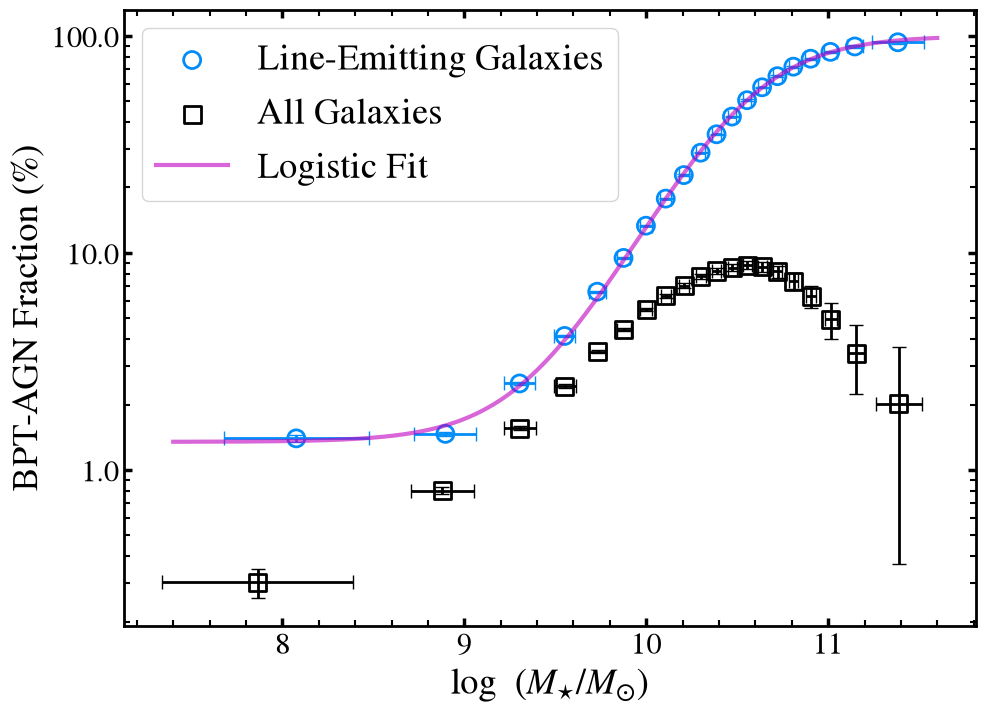

In [23]:
all_color = 'k'
leg_color = '#008df9'

plt.figure(figsize = (11, 8))
plt.scatter(logmass_leg, agnfrac_leg*100, marker = 'o', edgecolor = leg_color, lw = 2.0, s = 150, facecolor = 'none', label = 'Line-Emitting Galaxies')
plt.errorbar(logmass_leg, agnfrac_leg*100, xerr = logmass_leg_err, yerr = agnfrac_leg_err*100, ecolor = leg_color, fmt = 'none', lw = 2.0, capsize = 5.0)
plt.scatter(logmass_tot, agnfrac_all*100, marker = 's', edgecolor = all_color, s = 150, lw = 2.0, facecolor = 'none', label = 'All Galaxies')
plt.errorbar(logmass_tot, agnfrac_all*100, xerr = logmass_tot_err, yerr = agnfrac_leg_err*100, ecolor = all_color, fmt = 'none', lw = 2.0, capsize = 5.0)

plt.plot(xfit, yfit, color = 'm', lw = 3.0, ls = '-', alpha = 0.6, label = 'Logistic Fit')
plt.ylabel('BPT-AGN Fraction (%)', fontsize = 26)
plt.xlabel('$\log~(M_{\star}/M_{\odot})$', fontsize = 26)
plt.yscale('log')
plt.gca().yaxis.set_major_formatter(ScalarFormatter())

plt.legend(loc = 'upper left', fontsize = 26)
# plt.savefig('agnfrac_mstar.png')

---